In [10]:
import os, sys, shutil
if not os.path.exists("em.py") and os.path.exists("../em.py"):
    os.chdir("..")
sys.path.insert(0, os.getcwd())
print("Pasta de trabalho:", os.getcwd())

if not os.path.exists("auto_infracao_2021.csv"):
    try:
        os.symlink(os.path.join("dados", "auto_infracao_2021.csv"), "auto_infracao_2021.csv")
    except OSError:
        shutil.copy(os.path.join("dados", "auto_infracao_2021.csv"), "auto_infracao_2021.csv")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import GroupKFold, GroupShuffleSplit

import trabalho_etapas_3_4_bayes as projeto          # Naive Bayes do zero (Membro 3)
from em import MisturaGaussianaEM, adicionar_Z, z_para_matriz, plotar_loglik, teste_sintetico

SEED = 42
np.random.seed(SEED)

Pasta de trabalho: c:\Users\hagat\Downloads\2o-Trab-SimbML-Incerteza_equipe_3-main\2o-Trab-SimbML-Incerteza_equipe_3-main


In [11]:
COLS_CLIMA = ["precip_mm", "temp_media", "umid_media"]            # entrada do EM
COLS_RAW = ['DES_AUTO_INFRACAO', 'UF', 'DS_BIOMAS_ATINGIDOS', 'TP_PESSOA_INFRATOR']

inmet = pd.read_csv("dados/inmet_uf_mes.csv", encoding="utf-8-sig")
inmet = inmet[inmet["ano"] == 2021]

def clima_de(df_raw):
    """Clima (chuva, temp, umidade) de cada auto, pela UF e pelo mês da infração.
    Devolve um DataFrame na MESMA ORDEM das linhas de df_raw."""
    d = pd.DataFrame({
        "UF": df_raw["UF"].values,
        "mes": pd.to_datetime(df_raw["DAT_HORA_AUTO_INFRACAO"], errors="coerce").dt.month.values,
    })
    return d.merge(inmet[["UF", "mes"] + COLS_CLIMA], on=["UF", "mes"], how="left")[COLS_CLIMA].reset_index(drop=True)

idx = np.arange(len(projeto.df_bruto))
grupos = projeto.identificar_grupos(projeto.df_bruto)
idx_tr, idx_te = next(GroupShuffleSplit(n_splits=1, test_size=0.30, random_state=42).split(idx, groups=grupos))
df_treino_bruto = projeto.df_treino_bruto
df_teste_bruto = projeto.df_bruto.iloc[idx_te]
assert (projeto.df_bruto.iloc[idx_tr].index == df_treino_bruto.index).all(), "divisão diferente da Membro 3"
assert len(df_teste_bruto) == len(projeto.y_te)

clima_treino = clima_de(df_treino_bruto)
print("Autos no treino:", len(df_treino_bruto), "| no teste externo:", len(df_teste_bruto))
print("Treino com clima completo:", f"{clima_treino.notna().all(axis=1).mean():.1%}")
print("Limiar de multa alta (treino):", projeto.formatar_reais(projeto.LIMIAR_MULTA))
clima_treino.describe().round(1)

Autos no treino: 1529 | no teste externo: 660
Treino com clima completo: 94.0%
Limiar de multa alta (treino): R$ 145.000,00


,precip_mm,temp_media,umid_media
count,1438.0,1486.0,1486.0
mean,140.7,25.4,73.6
std,108.2,2.5,10.9
min,0.0,12.7,38.6
25%,55.9,24.8,68.1
50%,115.4,26.3,76.5
75%,230.7,26.5,82.4
max,427.6,29.6,90.1


=== TESTE SINTETICO ===
medias reais   : [0, 0] e [5, 4]   | pesos reais: 0.60 e 0.40
medias achadas : [[0.05, 0.01], [5.01, 3.97]] | pesos: [0.6 0.4]
iteracoes: 92 | loglik so sobe? True


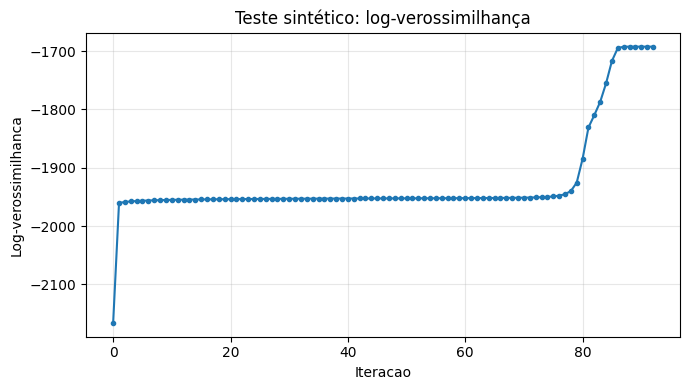

In [12]:
m_teste = teste_sintetico()
plotar_loglik(m_teste.loglik_, titulo="Teste sintético: log-verossimilhança")

In [13]:
d = clima_treino.dropna()
media, desvio = d.values.mean(axis=0), d.values.std(axis=0)
K = 2
em = MisturaGaussianaEM(K=K, seed=SEED).fit((d.values - media) / desvio)

print(f"Convergiu em {em.n_iter_} iterações")
print("A log-verossimilhança só sobe?", bool(np.all(np.diff(em.loglik_) > -1e-8)))
tabela = pd.DataFrame(em.mu_ * desvio + media, columns=COLS_CLIMA, index=[f"Z{k}" for k in range(K)]).round(1)
tabela.insert(0, "peso", np.round(em.theta_, 3))
tabela

Convergiu em 32 iterações
A log-verossimilhança só sobe? True


,peso,precip_mm,temp_media,umid_media
Z0,0.406,54.1,24.3,64.5
Z1,0.594,199.9,26.1,79.9


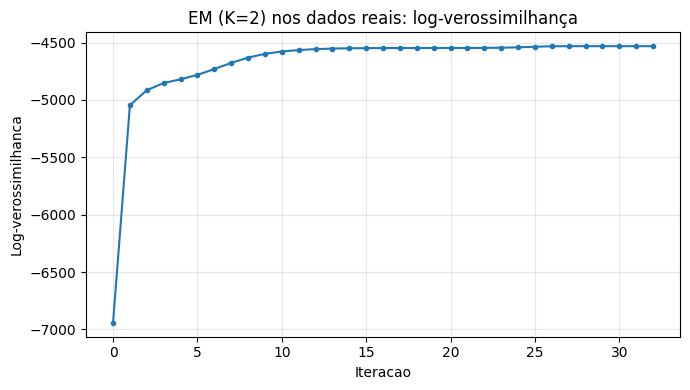

In [14]:
plotar_loglik(em.loglik_, titulo=f"EM (K={K}) nos dados reais: log-verossimilhança", salvar="loglik_em.png")

In [15]:
def cv_acuracia(K, k=5):
    """Acurácia por fold. K=0: Naive Bayes puro. K>=2: Naive Bayes + Z com K grupos."""
    X_raw = df_treino_bruto[COLS_RAW]
    y_cont = df_treino_bruto["VALOR_NUMERICO"]
    grupos = projeto.identificar_grupos(df_treino_bruto)
    acuracias = []
    for i_fit, i_val in GroupKFold(n_splits=k).split(X_raw, groups=grupos):
        Xf, Xv, yf, yv, _, _, _ = projeto.preparar_particoes_ml(
            X_raw.iloc[i_fit], X_raw.iloc[i_val], y_cont.iloc[i_fit], y_cont.iloc[i_val])
        if K:
            cf, cv_, _ = adicionar_Z(clima_treino.iloc[i_fit].reset_index(drop=True),
                                     clima_treino.iloc[i_val].reset_index(drop=True),
                                     COLS_CLIMA, K=K)               # EM só no treino do fold
            Xf = np.hstack([Xf, z_para_matriz(cf["Z"], K)])
            Xv = np.hstack([Xv, z_para_matriz(cv_["Z"], K)])
        modelo = projeto.NaiveBayesRaiz().fit(Xf, yf)
        acuracias.append(projeto.acuracia(yv, modelo.predict(Xv)))
    return np.array(acuracias)

linhas = []
for nome, K in [("Naive Bayes puro", 0), ("+ Z (K=2)", 2), ("+ Z (K=3)", 3)]:
    a = cv_acuracia(K)
    linhas.append({"Configuração": nome, "Acurácia média": a.mean(), "Desvio": a.std(ddof=1)})
    print(f"{nome:18s} {a.mean():.2%} ± {a.std(ddof=1):.2%}")

resultado_cv = pd.DataFrame(linhas).round(4)
resultado_cv

Naive Bayes puro   83.78% ± 2.75%
+ Z (K=2)          83.13% ± 2.65%
+ Z (K=3)          83.45% ± 2.56%


,Configuração,Acurácia média,Desvio
0,Naive Bayes puro,0.8378,0.0275
1,+ Z (K=2),0.8313,0.0265
2,+ Z (K=3),0.8345,0.0256


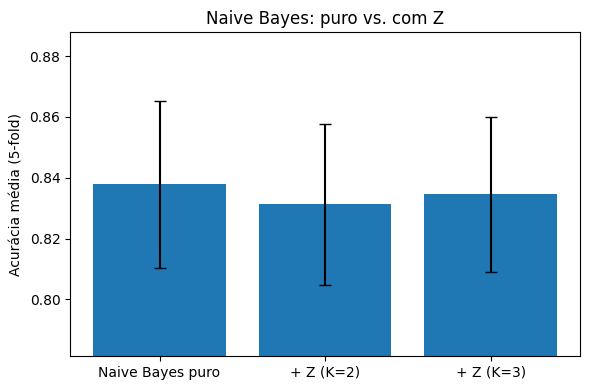

In [16]:
plt.figure(figsize=(6, 4))
plt.bar(resultado_cv["Configuração"], resultado_cv["Acurácia média"], yerr=resultado_cv["Desvio"], capsize=4)
plt.ylabel("Acurácia média (5-fold)")
plt.title("Naive Bayes: puro vs. com Z")
lo = max(0, resultado_cv["Acurácia média"].min() - 0.05)
plt.ylim(lo, min(1, resultado_cv["Acurácia média"].max() + 0.05))
plt.tight_layout()
plt.savefig("comparacao_nb_em.png", dpi=150)
plt.show()

In [17]:
clima_teste = clima_de(df_teste_bruto)
linhas = []
for nome, K in [("Naive Bayes puro", 0), ("+ Z (K=2)", 2), ("+ Z (K=3)", 3)]:
    Xf, Xt = projeto.X_tr, projeto.X_te
    if K:
        ctr, cte, _ = adicionar_Z(clima_treino, clima_teste, COLS_CLIMA, K=K)
        Xf = np.hstack([Xf, z_para_matriz(ctr["Z"], K)])
        Xt = np.hstack([Xt, z_para_matriz(cte["Z"], K)])
    modelo = projeto.NaiveBayesRaiz().fit(Xf, projeto.y_tr)
    linhas.append({"Configuração": nome, "Acurácia no teste": projeto.acuracia(projeto.y_te, modelo.predict(Xt))})

pd.DataFrame(linhas).round(4)

,Configuração,Acurácia no teste
0,Naive Bayes puro,0.8591
1,+ Z (K=2),0.8485
2,+ Z (K=3),0.8485
